
# Evaluare 01: Învățarea supervizată
Acest test are scopul de a evalua cunoștințele tale despre importul datelor, vizualizarea acestora și utilizarea modelelor de machine learning.
Te rugăm să completezi cerințele direct în celulele dedicate fiecărei secțiuni.


**Comparație cu împărțirea oficială.** Aceiași parametri ca în soluția inițială, dar antrenarea folosește train.csv (7.352 rânduri), iar testarea test.csv (2.947 rânduri). Această variantă verifică efectul împărțirii datelor; nu respectă proporția 80/20 din enunț. Identificatorii de persoane sunt disjuncți între cele două fișiere.

## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.


In [1]:
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid')
SEED = 42
archive = Path('archive (2).zip')
if not archive.exists():
    archive = Path.home() / 'Downloads' / 'archive (2).zip'
with ZipFile(archive) as z:
    train_df = pd.read_csv(z.open('train.csv'))
    test_df = pd.read_csv(z.open('test.csv'))
# Nume unice și identice cu cele din prima soluție, în aceeași ordine.
raw_features = [c for c in train_df.columns if c not in ['subject', 'Activity']]
feature_cols = [f'{i+1:03d}_{c}' for i, c in enumerate(raw_features)]
mapping = dict(zip(raw_features, feature_cols))
mapping['subject'] = 'Subject'
train_df = train_df.rename(columns=mapping)
test_df = test_df.rename(columns=mapping)
df = pd.concat([train_df, test_df], ignore_index=True)
assert set(train_df.Subject).isdisjoint(set(test_df.Subject))
print('Dimensiuni:', df.shape, '; train:', train_df.shape, '; test:', test_df.shape)
print('Persoane diferite în train și test:', sorted(train_df.Subject.unique()), sorted(test_df.Subject.unique()))
display(df.dtypes.to_frame('tip'))
display(df.head())
print('Valori lipsă:', df.isna().sum().sum())
display(df.Activity.value_counts())


,tip
001_tBodyAcc-mean()-X,float64
002_tBodyAcc-mean()-Y,float64
003_tBodyAcc-mean()-Z,float64
004_tBodyAcc-std()-X,float64
005_tBodyAcc-std()-Y,float64
...,...
"559_angle(X,gravityMean)",float64
"560_angle(Y,gravityMean)",float64
"561_angle(Z,gravityMean)",float64
Subject,int64


,001_tBodyAcc-mean()-X,002_tBodyAcc-mean()-Y,003_tBodyAcc-mean()-Z,004_tBodyAcc-std()-X,005_tBodyAcc-std()-Y,006_tBodyAcc-std()-Z,007_tBodyAcc-mad()-X,008_tBodyAcc-mad()-Y,009_tBodyAcc-mad()-Z,010_tBodyAcc-max()-X,011_tBodyAcc-max()-Y,012_tBodyAcc-max()-Z,013_tBodyAcc-min()-X,014_tBodyAcc-min()-Y,015_tBodyAcc-min()-Z,016_tBodyAcc-sma(),017_tBodyAcc-energy()-X,018_tBodyAcc-energy()-Y,019_tBodyAcc-energy()-Z,020_tBodyAcc-iqr()-X,021_tBodyAcc-iqr()-Y,022_tBodyAcc-iqr()-Z,023_tBodyAcc-entropy()-X,024_tBodyAcc-entropy()-Y,025_tBodyAcc-entropy()-Z,"026_tBodyAcc-arCoeff()-X,1","027_tBodyAcc-arCoeff()-X,2","028_tBodyAcc-arCoeff()-X,3","029_tBodyAcc-arCoeff()-X,4","030_tBodyAcc-arCoeff()-Y,1","031_tBodyAcc-arCoeff()-Y,2","032_tBodyAcc-arCoeff()-Y,3","033_tBodyAcc-arCoeff()-Y,4","034_tBodyAcc-arCoeff()-Z,1","035_tBodyAcc-arCoeff()-Z,2","036_tBodyAcc-arCoeff()-Z,3","037_tBodyAcc-arCoeff()-Z,4","038_tBodyAcc-correlation()-X,Y","039_tBodyAcc-correlation()-X,Z","040_tBodyAcc-correlation()-Y,Z",...,524_fBodyBodyAccJerkMag-entropy(),525_fBodyBodyAccJerkMag-maxInds,526_fBodyBodyAccJerkMag-meanFreq(),527_fBodyBodyAccJerkMag-skewness(),528_fBodyBodyAccJerkMag-kurtosis(),529_fBodyBodyGyroMag-mean(),530_fBodyBodyGyroMag-std(),531_fBodyBodyGyroMag-mad(),532_fBodyBodyGyroMag-max(),533_fBodyBodyGyroMag-min(),534_fBodyBodyGyroMag-sma(),535_fBodyBodyGyroMag-energy(),536_fBodyBodyGyroMag-iqr(),537_fBodyBodyGyroMag-entropy(),538_fBodyBodyGyroMag-maxInds,539_fBodyBodyGyroMag-meanFreq(),540_fBodyBodyGyroMag-skewness(),541_fBodyBodyGyroMag-kurtosis(),542_fBodyBodyGyroJerkMag-mean(),543_fBodyBodyGyroJerkMag-std(),544_fBodyBodyGyroJerkMag-mad(),545_fBodyBodyGyroJerkMag-max(),546_fBodyBodyGyroJerkMag-min(),547_fBodyBodyGyroJerkMag-sma(),548_fBodyBodyGyroJerkMag-energy(),549_fBodyBodyGyroJerkMag-iqr(),550_fBodyBodyGyroJerkMag-entropy(),551_fBodyBodyGyroJerkMag-maxInds,552_fBodyBodyGyroJerkMag-meanFreq(),553_fBodyBodyGyroJerkMag-skewness(),554_fBodyBodyGyroJerkMag-kurtosis(),"555_angle(tBodyAccMean,gravity)","556_angle(tBodyAccJerkMean),gravityMean)","557_angle(tBodyGyroMean,gravityMean)","558_angle(tBodyGyroJerkMean,gravityMean)","559_angle(X,gravityMean)","560_angle(Y,gravityMean)","561_angle(Z,gravityMean)",Subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,-0.567378,-0.744413,0.852947,0.685845,0.814263,-0.965523,-0.999945,-0.999863,-0.994612,-0.994231,-0.987614,-0.943220,-0.407747,-0.679338,-0.602122,0.929294,-0.853011,0.359910,-0.058526,0.256892,-0.224848,0.264106,-0.095246,0.278851,-0.465085,0.491936,-0.190884,0.376314,0.435129,0.660790,...,-1.0,-0.936508,0.346989,-0.516080,-0.802760,-0.980135,-0.961309,-0.973653,-0.952264,-0.989498,-0.980135,-0.999240,-0.992656,-0.701291,-1.000000,-0.128989,0.586156,0.374605,-0.991990,-0.990697,-0.989941,-0.992448,-0.991048,-0.991990,-0.999937,-0.990458,-0.871306,-1.000000,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,-0.557851,-0.818409,0.849308,0.685845,0.822637,-0.981930,-0.999991,-0.999788,-0.998405,-0.999150,-0.977866,-0.948225,-0.714892,-0.500930,-0.570979,0.611627,-0.329549,0.284213,0.284595,0.115705,-0.090963,0.294310,-0.281211,0.085988,-0.022153,-0.016657,-0.220643,-0.013429,-0.072692,0.579382,...,-1.0,-0.841270,0.532061,-0.624871,-0.900160,-0.988296,-0.983322,-0.982659,-0.986321,-0.991829,-0.988296,-0.999811,-0.993979,-0.720683,-0.948718,-0.271958,-0.336310,-0.720015,-0.995854,-0.996399,-0.995442,-0.996866,-0.994440,-0.995854,-0.999981,-0.994544,-1.000000,-1.000000,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,-0.557851,-0.818409,0.843609,0.682401,0.839344,-0.983478,-0.999969,-0.999660,-0.999470,-0.997130,-0.964810,-0.974675,-

Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Dimensiuni: (10299, 563) ; train: (7352, 563) ; test: (2947, 563)
Persoane diferite în train și test: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)] [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Valori lipsă: 0



## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numeric.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.


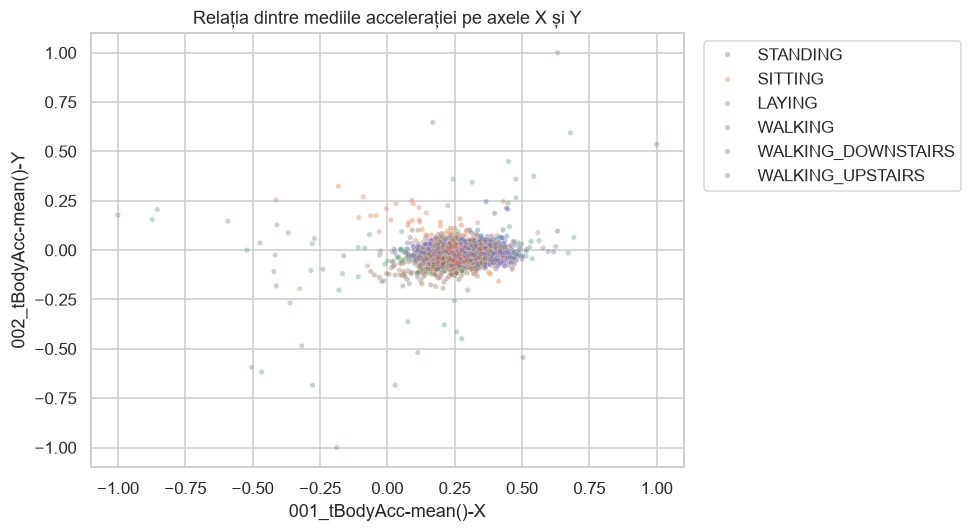

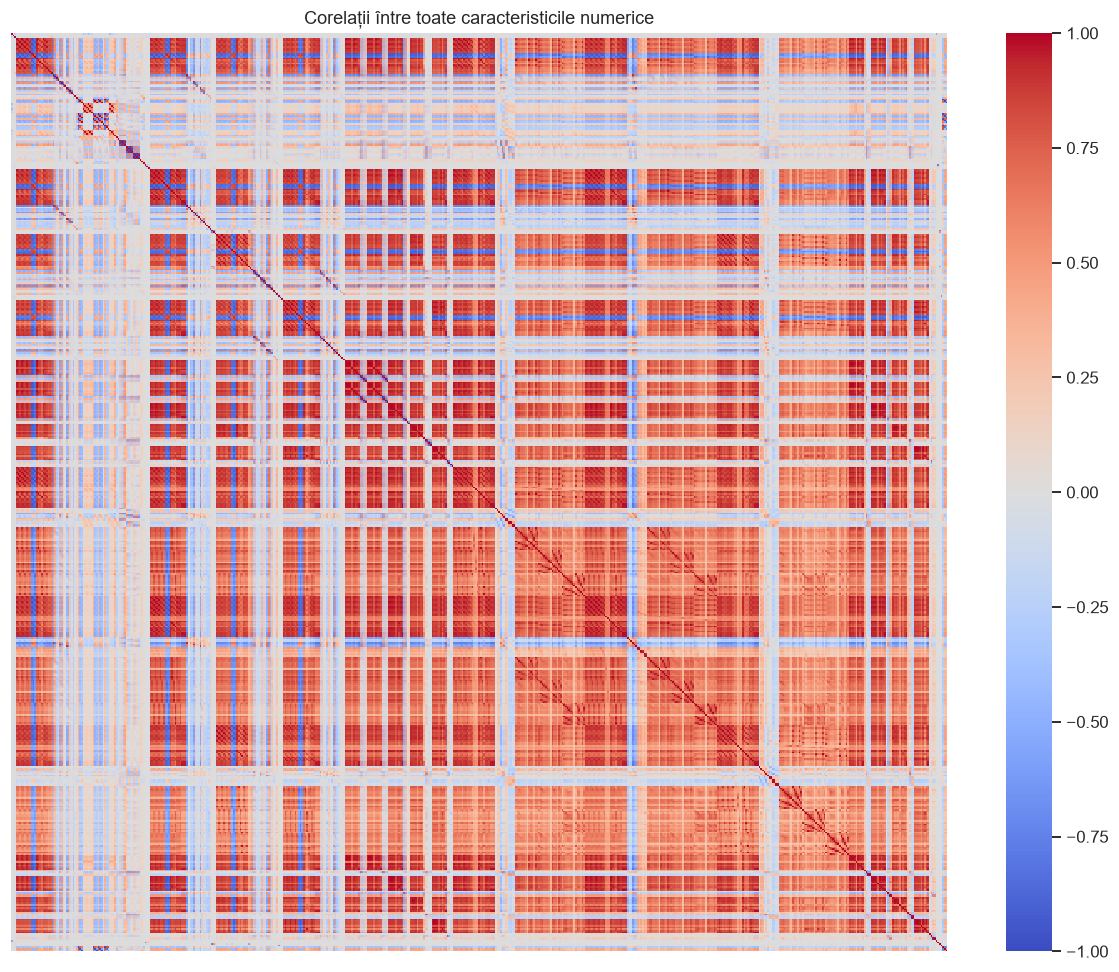

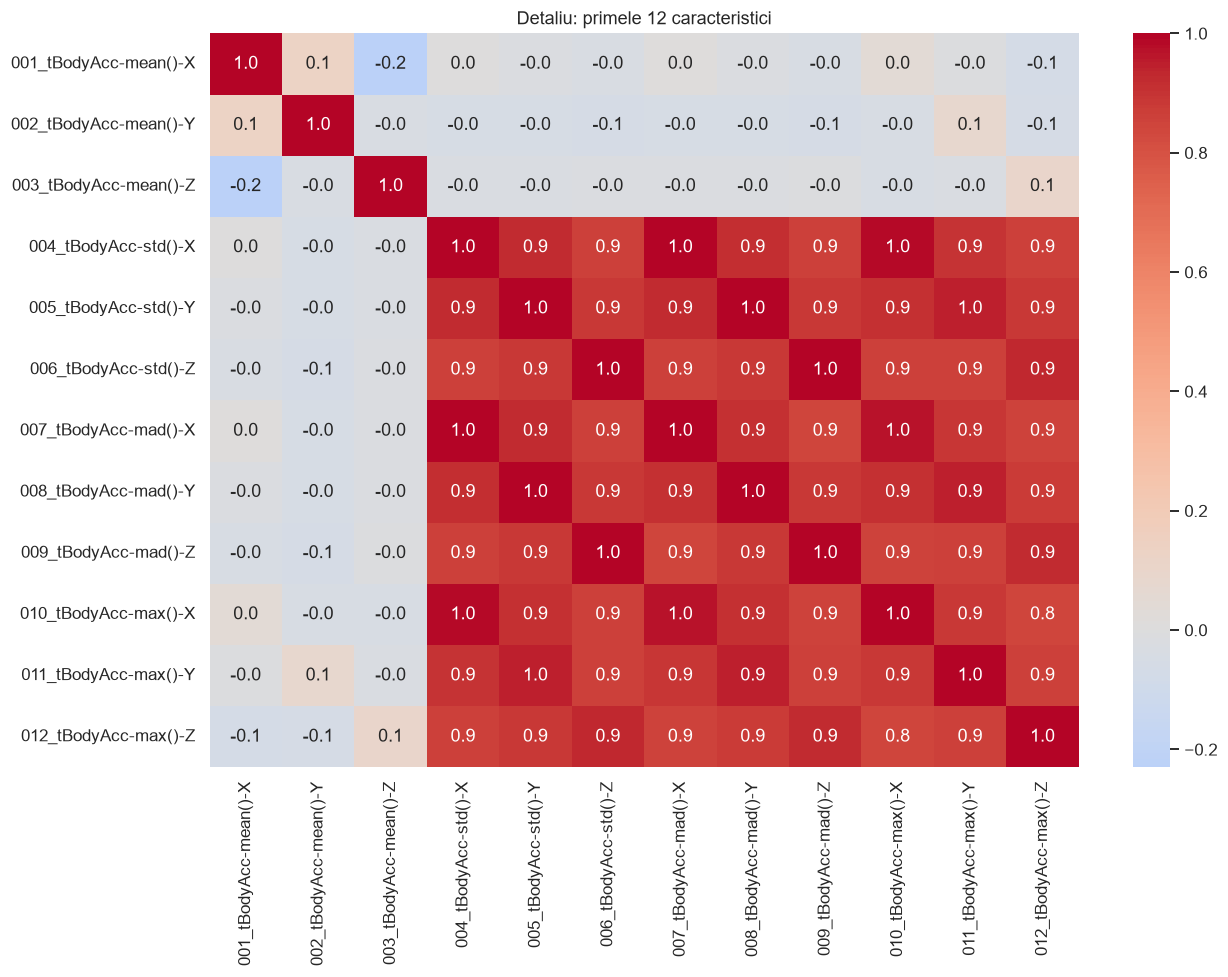

In [2]:
x_col, y_col = feature_cols[0], feature_cols[1]
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x=x_col, y=y_col, hue='Activity', s=12, alpha=.4)
plt.title('Relația dintre mediile accelerației pe axele X și Y')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()
# Matricea completă include toate cele 561 de caracteristici numerice.
corr = df[feature_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False)
plt.title('Corelații între toate caracteristicile numerice'); plt.tight_layout(); plt.show()
# Detaliu lizibil pentru primele 12 caracteristici.
plt.figure(figsize=(12, 9))
sns.heatmap(corr.iloc[:12, :12], cmap='coolwarm', center=0, annot=True, fmt='.1f')
plt.title('Detaliu: primele 12 caracteristici'); plt.tight_layout(); plt.show()


## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE**, și **RMSE**.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report

# Activity este categorică: nu o codificăm numeric pentru regresie.
# Prezicem media accelerației pe axa X din celelalte măsurători.
reg_target = feature_cols[0]
X_reg = df[[c for c in feature_cols if c != reg_target]]
y_reg = df[reg_target]
Xr_train, Xr_test = train_df[X_reg.columns], test_df[X_reg.columns]
yr_train, yr_test = train_df[reg_target], test_df[reg_target]
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(Xr_train, yr_train)
reg_pred = linear_model.predict(Xr_test)
reg_metrics = {'MAE': mean_absolute_error(yr_test, reg_pred),
               'MSE': mean_squared_error(yr_test, reg_pred),
               'RMSE': np.sqrt(mean_squared_error(yr_test, reg_pred)),
               'R²': r2_score(yr_test, reg_pred)}
print('Ținta numerică:', reg_target)
print('Antrenare / testare:', len(Xr_train), len(Xr_test))
display(pd.Series(reg_metrics, name='Regresie liniară').to_frame())
print('MAE și RMSE sunt în unitățile țintei normalizate; valori mai mici indică erori mai mici.')


,Regresie liniară
MAE,0.023576
MSE,0.001078
RMSE,0.032839
R²,0.705952


Ținta numerică: 001_tBodyAcc-mean()-X
Antrenare / testare: 7352 2947
MAE și RMSE sunt în unitățile țintei normalizate; valori mai mici indică erori mai mici.



## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.


In [4]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

X = df[feature_cols]
y = df['Activity']
X_train, X_test = train_df[feature_cols], test_df[feature_cols]
y_train, y_test = train_df.Activity, test_df.Activity
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=1))
# Scalarea se învață separat în fiecare fold; testul rămâne separat.
scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=1)
print('Acuratețe pe cele 5 folduri:', scores)
print(f'Medie CV: {scores.mean():.4f}; abatere standard: {scores.std():.4f}')
knn.fit(X_train, y_train)
print(f'Acuratețe KNN pe test: {knn.score(X_test, y_test):.4f}')
print('Testul oficial conține persoane nevăzute la antrenare. CV stratificat este păstrat ca în prima variantă și poate amesteca persoane între folduri.')


Acuratețe pe cele 5 folduri: [0.96804895 0.96397009 0.95714286 0.96190476 0.95442177]
Medie CV: 0.9611; abatere standard: 0.0048
Acuratețe KNN pe test: 0.8836
Testul oficial conține persoane nevăzute la antrenare. CV stratificat este păstrat ca în prima variantă și poate amesteca persoane între folduri.



## 5. Modele de Machine Learning
1. **Regresia liniară**: Antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: Construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: Antrenează un model SVM și testează-l pe setul de date.


,Test
MAE,0.023576
MSE,0.001078
RMSE,0.032839
R²,0.705952


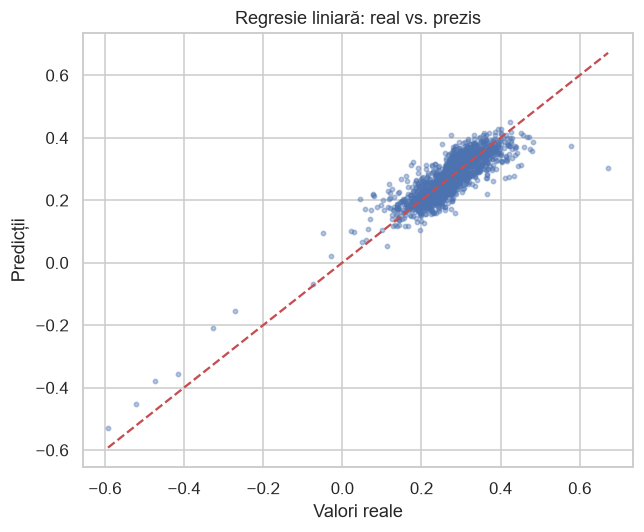

In [5]:
# 5.1 Regresia liniară: modelul antrenat în secțiunea 3.
display(pd.Series(reg_metrics, name='Test').to_frame())
plt.figure(figsize=(6, 5)); plt.scatter(yr_test, reg_pred, s=8, alpha=.4)
lims = [min(yr_test.min(), reg_pred.min()), max(yr_test.max(), reg_pred.max())]
plt.plot(lims, lims, 'r--'); plt.xlabel('Valori reale'); plt.ylabel('Predicții')
plt.title('Regresie liniară: real vs. prezis'); plt.tight_layout(); plt.show()


In [6]:
# 5.2 Clasificare binară: activitate dinamică (1) vs. statică (0).
dynamic = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS']
yb_train = y_train.isin(dynamic).astype(int)
yb_test = y_test.isin(dynamic).astype(int)
binary_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED))
binary_model.fit(X_train, yb_train)
binary_pred = binary_model.predict(X_test)
print(f'Acuratețe logistică binară: {accuracy_score(yb_test, binary_pred):.4f}')
print(classification_report(yb_test, binary_pred, target_names=['statică', 'dinamică']))


Acuratețe logistică binară: 0.9997
              precision    recall  f1-score   support

     statică       1.00      1.00      1.00      1560
    dinamică       1.00      1.00      1.00      1387

    accuracy                           1.00      2947
   macro avg       1.00      1.00      1.00      2947
weighted avg       1.00      1.00      1.00      2947



In [7]:
from sklearn.svm import SVC
# 5.3 SVM: clasificarea celor șase activități.
svm_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10))
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print(f'Acuratețe SVM: {accuracy_score(y_test, svm_pred):.4f}')
print(classification_report(y_test, svm_pred))


Acuratețe SVM: 0.9542
                    precision    recall  f1-score   support

            LAYING       0.99      1.00      1.00       537
           SITTING       0.96      0.89      0.93       491
          STANDING       0.91      0.97      0.94       532
           WALKING       0.95      0.97      0.96       496
WALKING_DOWNSTAIRS       0.97      0.92      0.94       420
  WALKING_UPSTAIRS       0.93      0.96      0.95       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



In [8]:
# Toate modelele folosesc random_state=42 unde este aplicabil, pentru reproductibilitate.


In [9]:
# Setul de test nu este folosit pentru ajustarea parametrilor sau antrenare.


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișează-o grafic utilizând Seaborn.

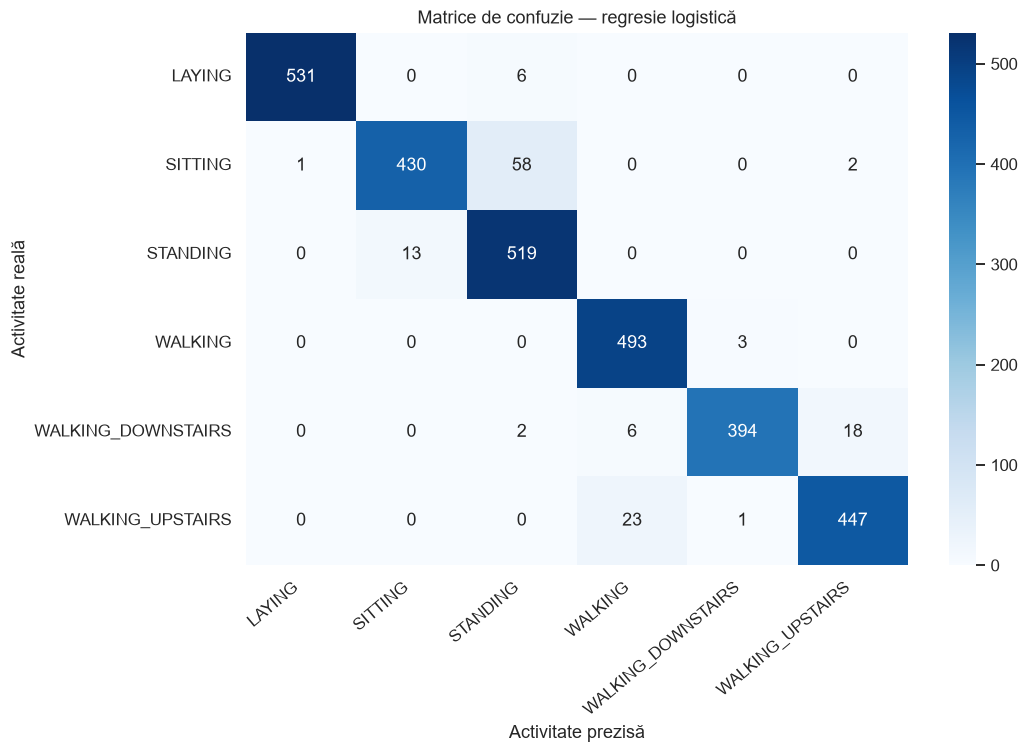

Acuratețe logistică multiclasa: 0.9549
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      0.99       537
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.98      0.93       532
           WALKING       0.94      0.99      0.97       496
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
  WALKING_UPSTAIRS       0.96      0.95      0.95       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



In [10]:
from sklearn.metrics import confusion_matrix
logistic_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED))
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)
classes = logistic_model.classes_
cm = confusion_matrix(y_test, logistic_pred, labels=classes)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Activitate prezisă'); plt.ylabel('Activitate reală')
plt.title('Matrice de confuzie — regresie logistică'); plt.xticks(rotation=40, ha='right')
plt.tight_layout(); plt.show()
print(f'Acuratețe logistică multiclasa: {accuracy_score(y_test, logistic_pred):.4f}')
print(classification_report(y_test, logistic_pred))



## 7. Gradient Descent
1. Implementați manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizați o funcție simplă $$J(\theta) = (\theta x - y)^2 $$ pe un subset al datelor.

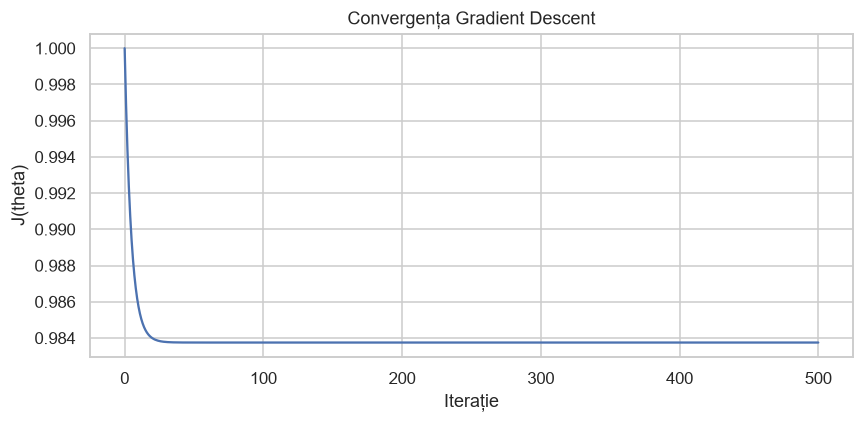

Cost inițial: 1.000000; cost final: 0.983747
Theta GD: 0.127489; soluția analitică: 0.127489


In [11]:
# J(theta) = media((theta*x - y)^2), fără intercept.
# Folosim un subset din train și standardizăm cele două variabile.
x_gd = Xr_train.iloc[:500, 0].to_numpy(dtype=float)
y_gd = yr_train.iloc[:500].to_numpy(dtype=float)
x_gd = (x_gd - x_gd.mean()) / x_gd.std()
y_gd = (y_gd - y_gd.mean()) / y_gd.std()
theta, learning_rate, n_iter = 0., .05, 500
costs = [np.mean((theta*x_gd-y_gd)**2)]
for step in range(n_iter):
    gradient = 2 * np.mean(x_gd * (theta*x_gd-y_gd))
    theta -= learning_rate * gradient
    costs.append(np.mean((theta*x_gd-y_gd)**2))
theta_exact = np.dot(x_gd, y_gd) / np.dot(x_gd, x_gd)
print(f'Cost inițial: {costs[0]:.6f}; cost final: {costs[-1]:.6f}')
print(f'Theta GD: {theta:.6f}; soluția analitică: {theta_exact:.6f}')
assert np.isclose(theta, theta_exact, atol=1e-6)
plt.figure(figsize=(8, 4)); plt.plot(costs)
plt.xlabel('Iterație'); plt.ylabel('J(theta)'); plt.title('Convergența Gradient Descent')
plt.tight_layout(); plt.show()


## 8. Modele de Machine Learning (part 2 - poate fi omis)
1. **Random Forest**: Utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: Compară performanța dintre un model AdaBoost și un model Bagging.


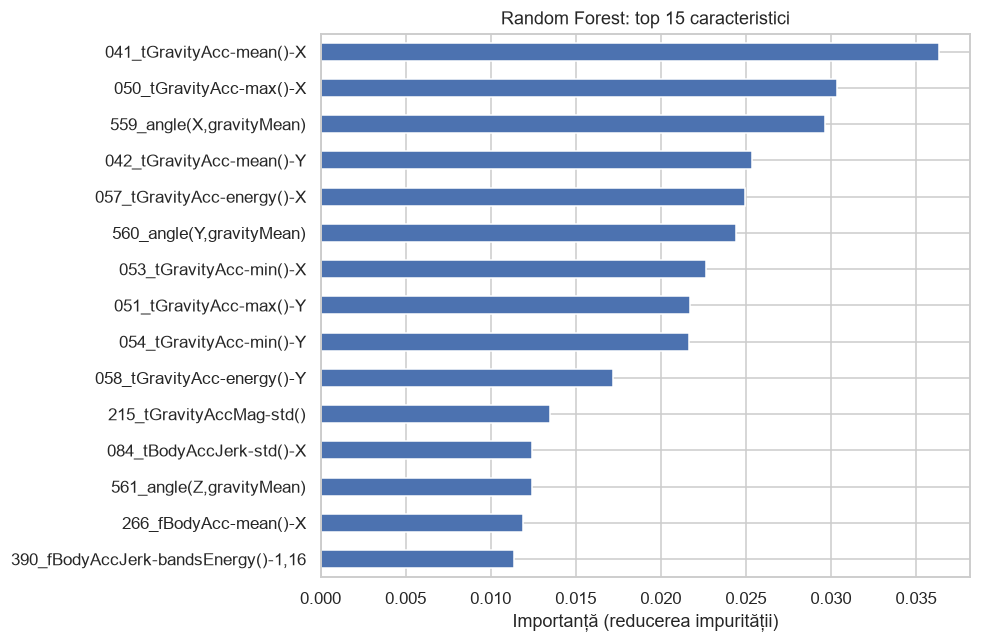

,Acuratețe test
Random Forest,0.926026
AdaBoost,0.901256
Bagging,0.896166


Comparația folosește aceleași date de test și parametrii declarați; nu reprezintă o căutare exhaustivă a parametrilor.


In [12]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1)
rf.fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=feature_cols).nlargest(15)
plt.figure(figsize=(9, 6)); importance.sort_values().plot.barh()
plt.xlabel('Importanță (reducerea impurității)'); plt.title('Random Forest: top 15 caracteristici')
plt.tight_layout(); plt.show()
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=60, random_state=SEED)
bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=40, random_state=SEED, n_jobs=1)
ada.fit(X_train, y_train); bag.fit(X_train, y_train)
ensemble_scores = {name: model.score(X_test, y_test) for name, model in [('Random Forest', rf), ('AdaBoost', ada), ('Bagging', bag)]}
display(pd.Series(ensemble_scores, name='Acuratețe test').to_frame())
print('Comparația folosește aceleași date de test și parametrii declarați; nu reprezintă o căutare exhaustivă a parametrilor.')



## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [13]:
from sklearn.ensemble import StackingClassifier
stack = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=80, random_state=SEED, n_jobs=1)),
        ('svm', make_pipeline(StandardScaler(), SVC(C=10, kernel='rbf'))),
        ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED)))],
    final_estimator=LogisticRegression(max_iter=3000, random_state=SEED),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)
# Meta-modelul se antrenează pe predicții out-of-fold, nu pe predicții din test.
stack.fit(X_train, y_train)
stack_pred = stack.predict(X_test)
print(f'Acuratețe finală Stacking: {accuracy_score(y_test, stack_pred):.4f}')
results = {'KNN': knn.score(X_test, y_test), 'Logistică': accuracy_score(y_test, logistic_pred),
           'SVM': accuracy_score(y_test, svm_pred), **ensemble_scores,
           'Stacking': accuracy_score(y_test, stack_pred)}
display(pd.Series(results, name='Acuratețe test').sort_values(ascending=False).to_frame())

print('Testarea oficială folosește persoane nevăzute la antrenare. Datele sunt aceleași, dar împărțirea și dimensiunile diferă de varianta 80/20.')
import json
summary = {'classification': results, 'regression': reg_metrics,
           'binary_logistic_accuracy': accuracy_score(yb_test, binary_pred),
           'knn_cv_mean': float(scores.mean()), 'knn_cv_std': float(scores.std()),
           'train_rows': len(X_train), 'test_rows': len(X_test)}
Path('rezultate_oficiale.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')


,Acuratețe test
Stacking,0.959281
Logistică,0.954869
SVM,0.954191
Random Forest,0.926026
AdaBoost,0.901256
Bagging,0.896166
KNN,0.883610


Acuratețe finală Stacking: 0.9593
Testarea oficială folosește persoane nevăzute la antrenare. Datele sunt aceleași, dar împărțirea și dimensiunile diferă de varianta 80/20.
